# 0. Data and concepts

Urban analysis combines data collected in different shapes: crashes as **points**, streets as
**lines**, districts and census tracts as **polygons**, heat and land cover as **rasters**, and
grids such as **H3**. urbanweave moves values between these shapes. This notebook introduces each
data model with a schematic drawing, then shows it in **Riverton**, the synthetic town the tutorials
use, so the later notebooks can concentrate on the operations.

The drawings use two colors with fixed meanings throughout: **orange for sources** (the data being
moved) and **blue for targets** (the places asked about).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly
import diagrams                     # schematic figures of the concepts

## Coordinates

Every geometry is a list of coordinates in a **coordinate reference system** (CRS). Lengths, areas
and distances only make sense in metres, so urbanweave measures each step in a projected CRS: the
one you give, or a local UTM zone it picks from the study area. Riverton is stored in UTM zone 18N
(EPSG:32618).

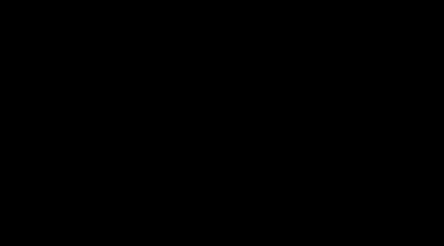

In [2]:
diagrams.coordinates()

## Vector data

Vector data describes features by their geometry: points, lines and polygons, each possibly made of
several parts. Most urbanweave methods accept some geometry families and not others; the registry
says which (notebook 1).

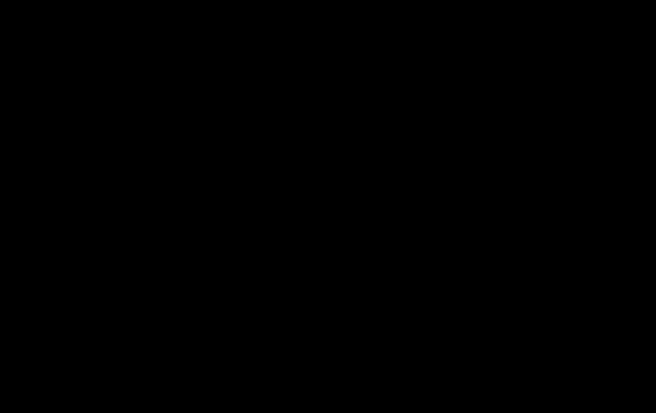

In [3]:
diagrams.geometry_types()

In Riverton, crashes and bus stops are points, districts and tracts are polygons:

In [4]:
layers = {"crashes": td.crashes(), "bus stops": td.bus_stops(), "districts": td.districts(), "tracts": td.tracts()}
pd.DataFrame({name: {"features": len(g), "geometry": ", ".join(sorted(set(g.geom_type))), "CRS": g.crs.to_string(),
                     "columns": ", ".join(c for c in g.columns if c != "geometry")}
              for name, g in layers.items()}).T

,features,geometry,CRS,columns
crashes,600,Point,EPSG:32618,"crash_id, persons_injured, hour, severity"
bus stops,14,Point,EPSG:32618,stop_id
districts,5,Polygon,EPSG:32618,"district_id, name"
tracts,18,Polygon,EPSG:32618,"tract_id, population, median_income"


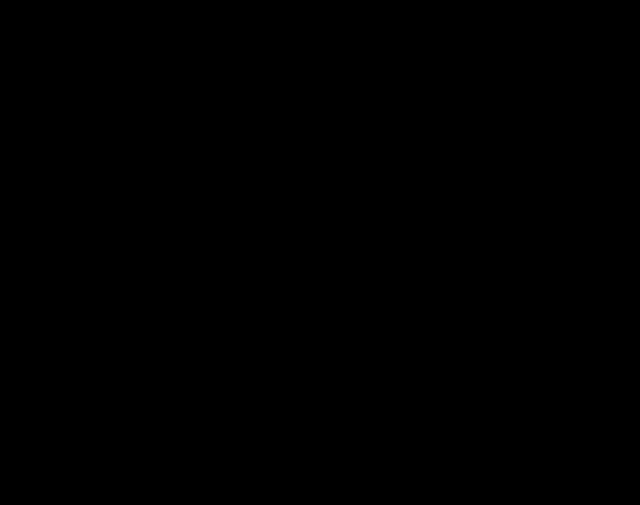

In [5]:
(Map("Riverton: tracts by population, districts, crashes and bus stops")
 .fill(layers["tracts"], "population", legend="people per tract", tooltip=["tract_id", "median_income"])
 .outline(layers["districts"], label="name", width=2)
 .dots(layers["crashes"], radius=1.3)
 .dots(layers["bus stops"], radius=4.5, label="stop_id"))

## Raster data

A raster is a grid of cells, each holding a value for the area it covers. It is defined by its
size (rows and columns), its cell size, where its corner lies, and its CRS. Cells without a
measurement are **nodata**: missing, not zero.

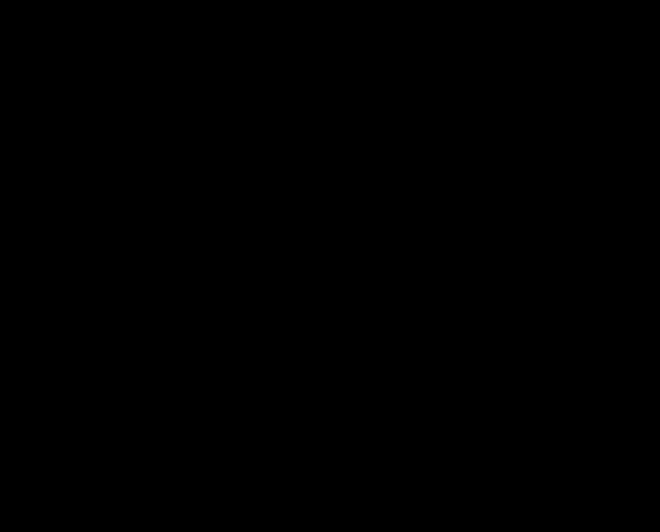

In [6]:
diagrams.raster_anatomy()

Riverton has two rasters on the same 10 m grid: the thermal comfort index UTCI, with a sensor gap,
and land cover. `read_raster` describes a raster without reading all of it:

In [7]:
heat, land = td.heat(), td.land_cover()
show(heat.describe())

{
 "crs": "EPSG:32618",
 "width": 300,
 "height": 200,
 "transform": [10.0, 0.0, 498500.0, 0.0, -10.0, 4501000.0],
 "bands": [
  {
   "index": 1,
   "name": "utci",
   "nodata": null,
   "scale": 1.0,
   "offset": 0.0,
   "value_kind": "intensive",
   "units": "degC"
  }
 ]
}


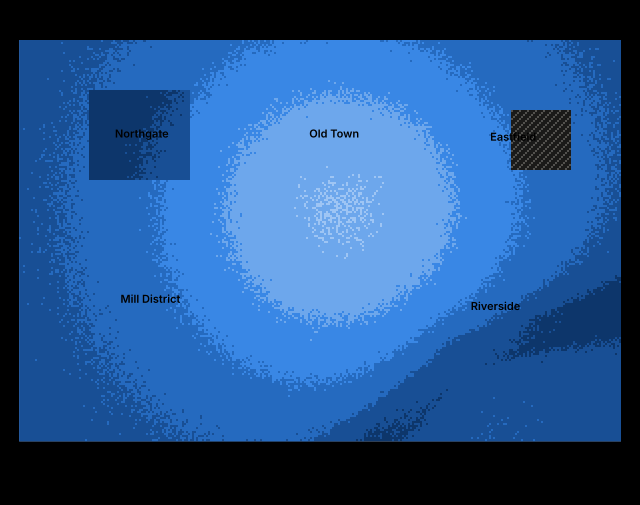

In [8]:
(Map("UTCI, 10 m cells")
 .raster(heat, legend="UTCI (°C)")
 .outline(layers["districts"], label="name", width=1.2))

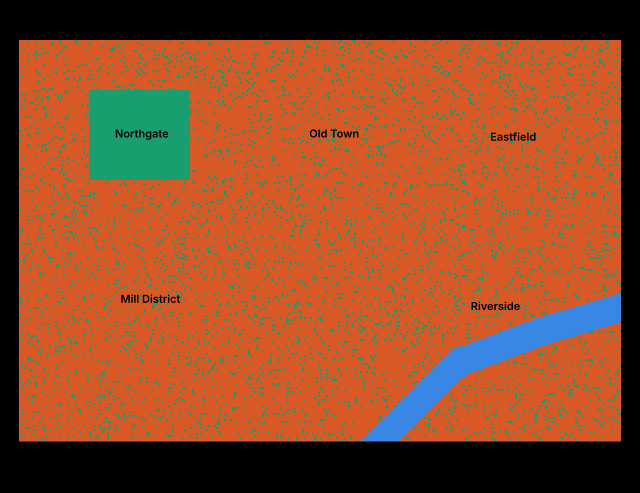

In [9]:
(Map("Land cover, 10 m cells")
 .raster(land, scheme="categorical", labels={1: "built", 2: "green", 3: "water"}, order=[3, 1, 2], legend="land cover")
 .outline(layers["districts"], label="name", width=1.2))

## H3: a raster whose cells have names

H3 tiles the Earth with hexagons at 16 resolutions. A set of H3 cells behaves like a raster (a
regular grid of cells) but each cell has a stable ID, so tables keyed by cell ID can be joined
without geometry. urbanweave treats H3 cells as a support of their own: points are matched by index
lookup, and a grid built over an extent keeps the cells whose centres fall inside it.

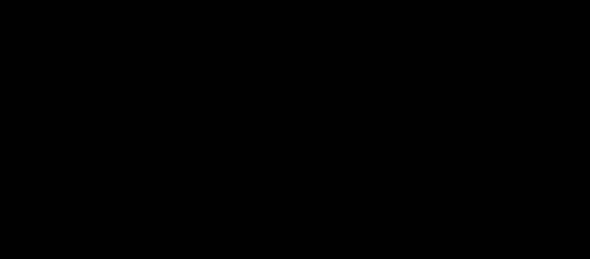

In [10]:
diagrams.h3_support()

52 cells at resolution 9; IDs like 892a12a9803ffff


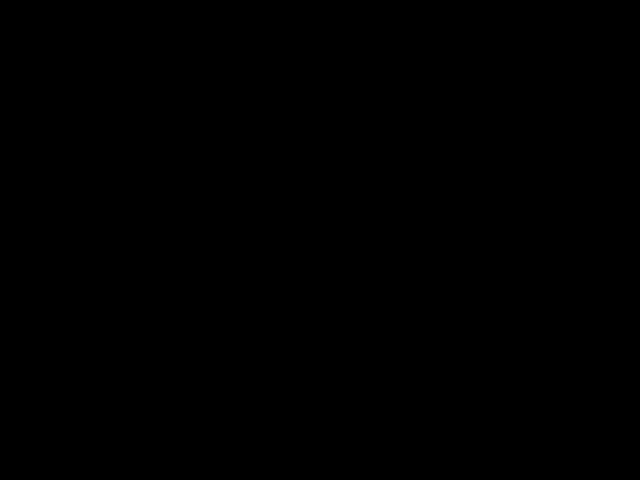

In [11]:
cells = uw.targets.h3_cells(layers["crashes"].to_crs(4326), 9)
print(len(cells), "cells at resolution 9; IDs like", cells["target_id"].iloc[0])
(Map("H3 resolution 9 over Riverton")
 .fill(cells)
 .outline(layers["districts"], label="name", width=1.6))

## Streets

Street networks come from OpenStreetMap through OSMnx as directed graphs. For measuring exposure
and density, urbanweave turns them into **physical segments**, one per piece of roadway, and
**intersections**, the nodes where three or more segments meet.

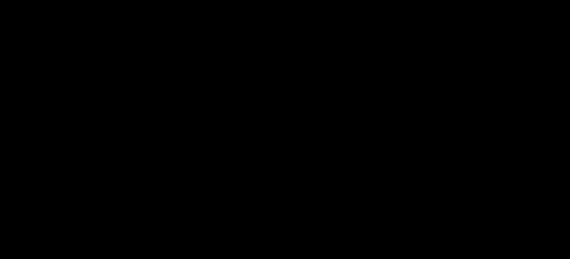

In [12]:
diagrams.street_graph()

224 physical segments, 56.0 km; 113 intersections


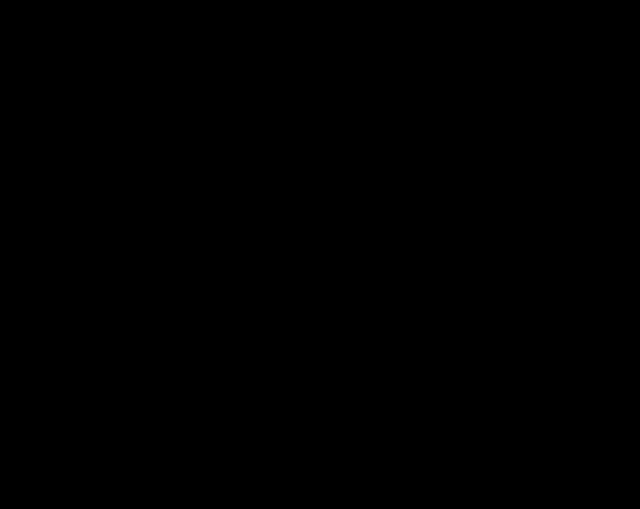

In [13]:
import os, tempfile
from urbanweave import streets as uws
path = os.path.join(tempfile.mkdtemp(), "riverton.graphml")
td.save_street_graph(path)
segments = uws.osm_streets(graphml=path)
nodes = uws.osm_intersections(graphml=path)
print(len(segments), "physical segments,", round(segments["length_m"].sum() / 1000, 1), "km;", len(nodes), "intersections")
(Map("Riverton's streets; intersections by the number of segments that meet")
 .lines(segments, width=1.4)
 .dots(nodes.assign(degree=nodes["degree"].astype(str)), "degree", scheme="categorical", order=["3", "4", "6"],
       radius=3.5, legend="segments meeting at the intersection")
 .note("Degree 6: Main Blvd's two carriageways plus the avenues."))

## How urbanweave moves data

Every step has two parts. **match** pairs sources with targets and measures what the pairing needs
(a fraction, an area or a length, a distance). **aggregate** turns the pairs into one row per
target. Both say what they did in a report.

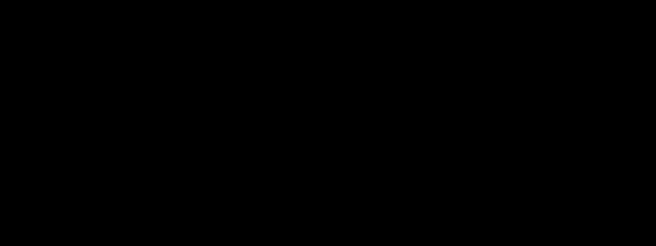

In [14]:
diagrams.match_and_aggregate()

How a value moves depends on what it measures. Counts and totals are split, averages and rates are
averaged by overlap, and categories become shares. Declaring a column's kind lets urbanweave refuse
a reduction that does not fit, such as summing median incomes.

The names *extensive* and *intensive* come from physics (mass adds when two systems are joined,
temperature does not) by way of geography, where they name totals that split with area and
ratios that do not; notebook 3 tells the story.

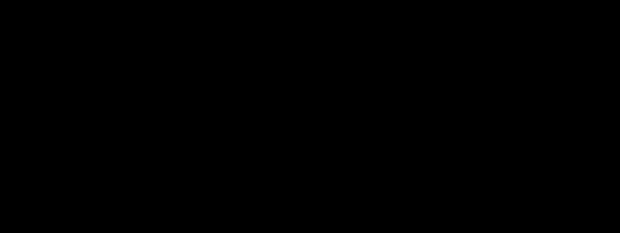

In [15]:
diagrams.value_kinds()

## Where to go next

1. [First steps](01_first_steps.ipynb): one complete example, points → H3 → districts.
2. [Matching methods](02_matching_methods.ipynb): every way to pair sources with targets.
3. [Aggregation and reports](03_aggregation_and_reports.ipynb): value kinds, missing values, coverage.
4. [H3 as a bridge](04_h3_as_a_bridge.ipynb): from a grid to polygons, points and lines.
5. [Rasters and zonal statistics](05_rasters_and_zonal_statistics.ipynb): exact coverage and cell centres.
6. [Streets](06_streets.ipynb): crashes per road-km and heat along the streets.
7. [Plans and replay](07_plans_and_replay.ipynb): recipes you can rerun and verify.